In [1]:
from google.colab import files
uploaded = files.upload()

Saving advanced_lithium_5yr_dataset.csv to advanced_lithium_5yr_dataset.csv


In [12]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Read already uploaded dataset
df = pd.read_csv('/content/advanced_lithium_5yr_dataset.csv')

print("Dataset Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nMissing Values:")
print(df.isnull().sum())

display(df.head())


Dataset Shape: (1048575, 28)

Columns: ['timestamp', 'ambient_temp_C', 'battery_temp_C', 'current_A', 'voltage_V', 'soc_%', 'soh_%', 'capacity_Ah', 'internal_resistance_ohm', 'cycle_count', 'calendar_aging_%', 'cycle_aging_%', 'temperature_stress_%', 'RUL_normalized', 'over_voltage_flag', 'under_voltage_flag', 'over_temperature_flag', 'voltage_roll_mean', 'voltage_roll_std', 'current_roll_mean', 'current_roll_std', 'temp_roll_mean', 'temp_roll_std', 'dV_dt', 'dT_dt', 'dSoC_dt', 'power_W', 'energy_Wh_cumulative']

Missing Values:
timestamp                  0
ambient_temp_C             0
battery_temp_C             0
current_A                  0
voltage_V                  0
soc_%                      0
soh_%                      0
capacity_Ah                0
internal_resistance_ohm    0
cycle_count                0
calendar_aging_%           0
cycle_aging_%              0
temperature_stress_%       0
RUL_normalized             0
over_voltage_flag          0
under_voltage_flag         0
o

,timestamp,ambient_temp_C,battery_temp_C,current_A,voltage_V,soc_%,soh_%,capacity_Ah,internal_resistance_ohm,cycle_count,...,voltage_roll_std,current_roll_mean,current_roll_std,temp_roll_mean,temp_roll_std,dV_dt,dT_dt,dSoC_dt,power_W,energy_Wh_cumulative
0,01-01-21,20.993428,20.668679,-3.507247,3.771202,50.000000,100.000000,2.500000,0.05,0.000000,...,0.000000,-3.507247,0.000000,20.668679,0.000000,0.000000,0.000000,0.000000,-13.226537,-0.220442
1,1/1/21 0:01,19.723710,21.165320,-0.848706,3.641096,50.565804,99.999883,2.499997,0.05,0.005658,...,0.091999,-2.177976,1.879872,20.916999,0.351178,-0.130107,0.496641,0.565804,-3.090220,-0.271946
2,1/1/21 0:02,21.295855,21.842970,2.163465,3.489040,49.123494,99.999591,2.499990,0.05,0.020081,...,0.141223,-0.730829,2.837193,21.225656,0.589466,-0.152056,0.677650,-1.442310,7.548417,-0.146139
3,1/1/21 0:03,23.046777,22.621924,-0.564716,3.623761,49.499971,99.999512,2.499988,0.05,0.023846,...,0.115417,-0.689301,2.318047,21.574723,0.847961,0.134721,0.778954,0.376477,-2.046394,-0.180246
4,1/1/21 0:04,19.532650,21.565621,-5.837468,3.905624,53.391616,99.998730,2.499968,0.05,0.062762,...,0.158254,-1.718934,3.054625,21.572903,0.734367,0.281863,-1.056303,3.891645,-22.798954,-0.560228


Simple Linear Regression
Intercept: 0.2955283554420376
Slope: 0.9992042268206894
MAE: 0.8374671481240448
RMSE: 1.0625392298419047
R2 Score: 0.9798081604577323
Missing values predicted: 0


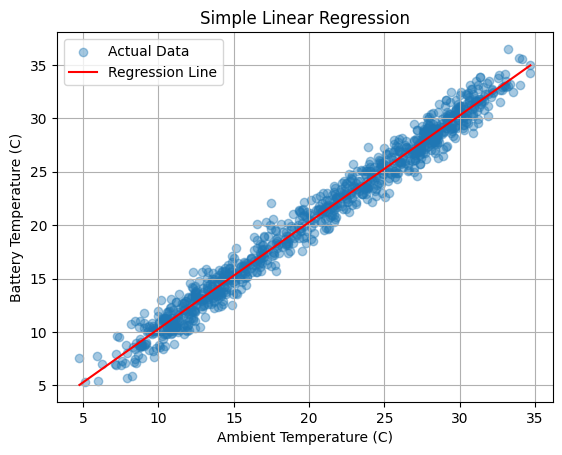

In [8]:



data = df[['ambient_temp_C', 'battery_temp_C']].copy()
data = data.apply(pd.to_numeric, errors='coerce')

complete = data.dropna()
missing = data[
    data['battery_temp_C'].isna() &
    data['ambient_temp_C'].notna()
]

sample = complete.sample(
    n=min(5000, len(complete)), random_state=42
)

train = sample.sample(frac=0.8, random_state=42)
test = sample.drop(train.index)

x = train['ambient_temp_C'].to_numpy()
y = train['battery_temp_C'].to_numpy()

x_mean = np.mean(x)
y_mean = np.mean(y)

w1 = np.sum((x-x_mean)*(y-y_mean)) / np.sum((x-x_mean)**2)
w0 = y_mean - w1*x_mean

y_actual = test['battery_temp_C'].to_numpy()
y_pred = w0 + w1*test['ambient_temp_C'].to_numpy()

mae = np.mean(np.abs(y_actual-y_pred))
rmse = np.sqrt(np.mean((y_actual-y_pred)**2))
r2 = 1 - np.sum((y_actual-y_pred)**2) / np.sum((y_actual-np.mean(y_actual))**2)

print("Simple Linear Regression")
print("Intercept:", w0)
print("Slope:", w1)
print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

df_simple = df.copy()
if len(missing) > 0:
    df_simple.loc[missing.index, 'battery_temp_C'] = (
        w0 + w1*missing['ambient_temp_C']
    )
print("Missing values predicted:", len(missing))

plt.scatter(test['ambient_temp_C'], y_actual,
            alpha=0.4, label="Actual Data")
order = np.argsort(test['ambient_temp_C'].to_numpy())
plt.plot(test['ambient_temp_C'].to_numpy()[order],
         y_pred[order], color='red', label="Regression Line")
plt.xlabel("Ambient Temperature (C)")
plt.ylabel("Battery Temperature (C)")
plt.title("Simple Linear Regression")
plt.legend()
plt.grid(True)
plt.show()


Multiple Linear Regression
Regression Coefficients: [ 0.18079971  0.9993103  -0.00501864  0.03128175]
MAE: 0.8383032480535585
RMSE: 1.063782624251435
R2 Score: 0.9797608754077388
Missing values predicted: 0


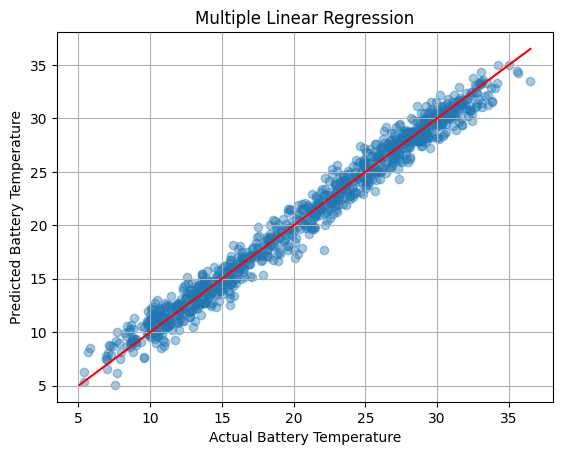

In [9]:


features = ['ambient_temp_C', 'current_A', 'voltage_V']
target = 'battery_temp_C'

data2 = df[features + [target]].copy()
data2 = data2.apply(pd.to_numeric, errors='coerce')

complete2 = data2.dropna()
missing2 = data2[
    data2[target].isna() &
    data2[features].notna().all(axis=1)
]

sample2 = complete2.sample(
    n=min(5000, len(complete2)), random_state=42
)

train2 = sample2.sample(frac=0.8, random_state=42)
test2 = sample2.drop(train2.index)

X_train = train2[features].to_numpy()
Y_train = train2[target].to_numpy()

X_train = np.column_stack((np.ones(len(X_train)), X_train))

b = np.linalg.pinv(X_train.T @ X_train) @ X_train.T @ Y_train

X_test = test2[features].to_numpy()
X_test = np.column_stack((np.ones(len(X_test)), X_test))

y_actual2 = test2[target].to_numpy()
y_pred2 = X_test @ b

mae2 = np.mean(np.abs(y_actual2-y_pred2))
rmse2 = np.sqrt(np.mean((y_actual2-y_pred2)**2))
r2_2 = 1 - np.sum((y_actual2-y_pred2)**2) / np.sum((y_actual2-np.mean(y_actual2))**2)

print("Multiple Linear Regression")
print("Regression Coefficients:", b)
print("MAE:", mae2)
print("RMSE:", rmse2)
print("R2 Score:", r2_2)

df_multiple = df.copy()
if len(missing2) > 0:
    X_missing = missing2[features].to_numpy()
    X_missing = np.column_stack(
        (np.ones(len(X_missing)), X_missing)
    )
    df_multiple.loc[missing2.index, target] = X_missing @ b

print("Missing values predicted:", len(missing2))

plt.scatter(y_actual2, y_pred2, alpha=0.4)
low = min(y_actual2.min(), y_pred2.min())
high = max(y_actual2.max(), y_pred2.max())
plt.plot([low, high], [low, high], color='red')
plt.xlabel("Actual Battery Temperature")
plt.ylabel("Predicted Battery Temperature")
plt.title("Multiple Linear Regression")
plt.grid(True)
plt.show()



In [10]:

comparison = pd.DataFrame({
    'Model': ['Simple Linear Regression',
              'Multiple Linear Regression'],
    'MAE': [mae, mae2],
    'RMSE': [rmse, rmse2],
    'R2 Score': [r2, r2_2]
})

print("Comparison of Regression Models")
display(comparison)

print("\nSimple Linear Regression uses 1 predictor.")
print("Multiple Linear Regression uses 3 predictors.")

print("\nLower MAE and RMSE indicate better predictions.")
print("Higher R2 generally indicates a better fit.")

best = comparison.loc[comparison['RMSE'].idxmin(), 'Model']
print("\nModel with lower RMSE:", best)


Comparison of Regression Models


,Model,MAE,RMSE,R2 Score
0,Simple Linear Regression,0.837467,1.062539,0.979808
1,Multiple Linear Regression,0.838303,1.063783,0.979761



Simple Linear Regression uses 1 predictor.
Multiple Linear Regression uses 3 predictors.

Lower MAE and RMSE indicate better predictions.
Higher R2 generally indicates a better fit.

Model with lower RMSE: Simple Linear Regression


In [11]:

print("Original missing battery temperatures:",
      df['battery_temp_C'].isna().sum())

print("\nAfter Simple Linear Regression:")
print(df_simple['battery_temp_C'].isna().sum())

print("\nAfter Multiple Linear Regression:")
print(df_multiple['battery_temp_C'].isna().sum())

print("\nSample of predicted values:")
display(df_multiple[
    ['ambient_temp_C', 'current_A',
     'voltage_V', 'battery_temp_C']
].head(10))


Original missing battery temperatures: 0

After Simple Linear Regression:
0

After Multiple Linear Regression:
0

Sample of predicted values:


,ambient_temp_C,current_A,voltage_V,battery_temp_C
0,20.993428,-3.507247,3.771202,20.668679
1,19.723710,-0.848706,3.641096,21.165320
2,21.295855,2.163465,3.489040,21.842970
3,23.046777,-0.564716,3.623761,22.621924
4,19.532650,-5.837468,3.905624,21.565621
5,19.532922,-2.983376,3.814149,19.794265
6,23.159860,-0.352752,3.691799,22.329442
7,21.536543,-0.154266,3.690062,22.486011
8,19.062964,1.722914,3.566376,19.696917
9,21.087272,-5.853548,3.983241,21.923463
